In [1]:

# 1. Install gdown
!pip -q install gdown

# 2. Download your Google Drive ZIP file
import gdown
import os

file_id = "1njl-hWUG7OEQVilJ4f8w77YuZe7EXrtM"
zip_path = "/kaggle/working/dataset.zip"

url = f"https://drive.google.com/uc?id={file_id}"

gdown.download(url, zip_path, quiet=False)

# 3. Verify the download
if os.path.exists(zip_path):
    print(f"Download complete: {zip_path}")
    print(f"File size: {os.path.getsize(zip_path) / (1024**3):.2f} GB")
else:
    print("Download failed. Check the Drive sharing permissions.")


Downloading...
From (original): https://drive.google.com/uc?id=1njl-hWUG7OEQVilJ4f8w77YuZe7EXrtM
From (redirected): https://drive.google.com/uc?id=1njl-hWUG7OEQVilJ4f8w77YuZe7EXrtM&confirm=t&uuid=7c2109e7-556a-46cf-809d-57ad40de9a47
To: /kaggle/working/dataset.zip
100%|██████████| 804M/804M [00:02<00:00, 284MB/s] 

Download complete: /kaggle/working/dataset.zip
File size: 0.75 GB


In [2]:

import zipfile
import os

zip_path = "/kaggle/working/dataset.zip"
extract_path = "/kaggle/working/dataset"

if os.path.isfile(zip_path) and zipfile.is_zipfile(zip_path):
    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(extract_path)
    print("Extracted to:", extract_path)
    print("Files:", os.listdir(extract_path)[:20])
else:
    print("ZIP file is missing, incomplete, or invalid.")


Extracted to: /kaggle/working/dataset
Files: ['noise_project_v2']


In [3]:

import os

folder = "/kaggle/working/dataset/noise_project_v2"

for root, dirs, files in os.walk(folder):
    level = root.replace(folder, "").count(os.sep)
    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")

    subindent = "    " * (level + 1)
    for file in files[:20]:
        print(f"{subindent}{file}")

    if level >= 3:
        dirs.clear()


noise_project_v2/
    clean_list.csv
    noisy_metadata_v2.csv
    b6000_split.csv
    noise_manifest_v2.json
    noisy_500_v2/
        U/
            00002456_U_500_roll_03.png
            00002550_U_500_roll_02.png
            00002375_U_500_roll_01.png
            00002560_U_500_roll_08.png
            00002604_U_500_roll_07.png
            00002314_U_500_roll_06.png
            00002394_U_500_roll_07.png
            00002437_U_500_roll_04.png
            00002348_U_500_roll_04.png
            00002472_U_500_roll_04.png
            00002575_U_500_roll_05.png
            00002493_U_500_roll_03.png
            00002420_U_500_roll_02.png
            00002435_U_500_roll_04.png
            00002328_U_500_roll_09.png
            00002448_U_500_roll_07.png
            00002423_U_500_roll_06.png
            00002625_U_500_roll_04.png
            00002578_U_500_roll_03.png
            00002516_U_500_roll_07.png
        R/
            00002337_R_500_slap_06.png
            00002374_R_500_slap

In [4]:

from pathlib import Path
from collections import Counter

folder = Path("/kaggle/working/dataset/noise_project_v2")

files = [p for p in folder.rglob("*") if p.is_file()]

print("Total files:", len(files))
print("\nFile types:")
print(Counter(p.suffix.lower() or "[no extension]" for p in files))

print("\nFirst 30 file paths:")
for p in files[:30]:
    print(p.relative_to(folder))


Total files: 4984

File types:
Counter({'.png': 4980, '.csv': 3, '.json': 1})

First 30 file paths:
clean_list.csv
noisy_metadata_v2.csv
b6000_split.csv
noise_manifest_v2.json
clean_500/U/00002456_U_500_roll_03.png
clean_500/U/00002550_U_500_roll_02.png
clean_500/U/00002375_U_500_roll_01.png
clean_500/U/00002560_U_500_roll_08.png
clean_500/U/00002604_U_500_roll_07.png
clean_500/U/00002314_U_500_roll_06.png
clean_500/U/00002394_U_500_roll_07.png
clean_500/U/00002437_U_500_roll_04.png
clean_500/U/00002348_U_500_roll_04.png
clean_500/U/00002472_U_500_roll_04.png
clean_500/U/00002575_U_500_roll_05.png
clean_500/U/00002493_U_500_roll_03.png
clean_500/U/00002420_U_500_roll_02.png
clean_500/U/00002435_U_500_roll_04.png
clean_500/U/00002328_U_500_roll_09.png
clean_500/U/00002448_U_500_roll_07.png
clean_500/U/00002423_U_500_roll_06.png
clean_500/U/00002625_U_500_roll_04.png
clean_500/U/00002578_U_500_roll_03.png
clean_500/U/00002516_U_500_roll_07.png
clean_500/U/00002625_U_500_roll_08.png
clean

In [5]:
import os, re, glob, random, subprocess, shutil, math, time
import numpy as np, pandas as pd
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity as ssim_fn
from tqdm.auto import tqdm

# ---------------- CONFIG: jo badalna ho yahin badlo ----------------
ROOT      = "/kaggle/working/dataset/noise_project_v2"
CLEAN_DIR = f"{ROOT}/clean_500"
NOISY_DIR = f"{ROOT}/noisy_500_v2"
OUT_DIR   = "/kaggle/working/lfrnet_out_official"   # official split ka alag folder
PATCH, BATCH, MULT = 384, 8, 4    # MULT: ek epoch mein har image se kitne patch
EPOCHS, LR, POWER  = 50, 2e-4, 0.9
LOSS_MODE = "l1ssim"              # "l1ssim" ya "mse"
USE_AMP   = True                  # skipped badhe ya NaN aaye to False kar do
SEED = 42
# --------------------------------------------------------------------
os.makedirs(OUT_DIR, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
AMP_ON = USE_AMP and DEVICE == "cuda"
print("device:", DEVICE, "| AMP:", AMP_ON, "| CPUs:", os.cpu_count())
if DEVICE == "cuda": print("GPU:", torch.cuda.get_device_name(0))

clean_files = sorted(glob.glob(f"{CLEAN_DIR}/**/*.png", recursive=True))
noisy_files = sorted(glob.glob(f"{NOISY_DIR}/**/*.png", recursive=True))
print("clean:", len(clean_files), "| noisy:", len(noisy_files))

device: cuda | AMP: True | CPUs: 4
GPU: Tesla T4
clean: 2490 | noisy: 2490


In [6]:
# --- file ke naam se clean aur noisy ko pair karo (naam: 00002302_R_500_slap_01) ---
PAT = re.compile(r"(\d+_[A-Za-z]_500_[A-Za-z]+_\d+)")
clean_map = {os.path.splitext(os.path.basename(p))[0]: p for p in clean_files}
pairs = []
for n in noisy_files:
    m = PAT.search(os.path.basename(n))
    if m and m.group(1) in clean_map:
        pairs.append((n, clean_map[m.group(1)], m.group(1).split("_")[0]))   # (noisy, clean, participant)
print("total pairs:", len(pairs))
assert len(pairs) > 0, "pairing fail hui: 3-4 noisy file ke naam mujhe bhejo"

# --- official split: CSV ke 'key' (clean file ka naam) aur 'split' column se ---
sp = pd.read_csv(f"{ROOT}/b6000_split.csv")
key_lab = dict(zip(sp["key"].astype(str), sp["split"].astype(str).str.lower().str.strip()))
buckets, missing = {"train": [], "val": [], "test": []}, 0
for p in pairs:
    stem = os.path.splitext(os.path.basename(p[1]))[0]
    lab_ = key_lab.get(stem)
    if lab_ in buckets: buckets[lab_].append(p)
    else: missing += 1
assert missing == 0, f"{missing} pairs ka split CSV mein nahi mila"
train_pairs, val_pairs, test_pairs = buckets["train"], buckets["val"], buckets["test"]
print(f"pairs train/val/test: {len(train_pairs)}/{len(val_pairs)}/{len(test_pairs)}   (1764/388/338)")

subj = lambda L: {p[2] for p in L}
print("participant overlap:",
      len(subj(train_pairs) & subj(test_pairs)), len(subj(train_pairs) & subj(val_pairs)), len(subj(val_pairs) & subj(test_pairs)))

total pairs: 2490
pairs train/val/test: 1764/388/338   (1764/388/338)
participant overlap: 0 0 0


In [7]:
def load_gray(path):
    
    return np.asarray(Image.open(path).convert("L"), dtype=np.float32) / 255.0

class PairPatchDataset(Dataset):
    def __init__(self, pairs, patch=PATCH, train=True, length_mult=1):
        self.pairs, self.patch, self.train, self.mult = pairs, patch, train, length_mult
    def __len__(self): return len(self.pairs) * self.mult
    def __getitem__(self, i):
        noisy_p, clean_p, _ = self.pairs[i % len(self.pairs)]
        x, y = load_gray(noisy_p), load_gray(clean_p)
        assert x.shape == y.shape, f"size match nahi: {noisy_p} {x.shape} vs {y.shape}"
        P = self.patch; H, W = x.shape
        mask = np.ones_like(x)
        ph, pw = max(0, P - H), max(0, P - W)
        if ph or pw:                                   # image chhoti hai: safed pad, mask=0 (loss mein nahi gina jayega)
            x = np.pad(x, ((0, ph), (0, pw)), constant_values=1.0)
            y = np.pad(y, ((0, ph), (0, pw)), constant_values=1.0)
            mask = np.pad(mask, ((0, ph), (0, pw)), constant_values=0.0)
            H, W = x.shape
        for _ in range(10):                            # fingerprint wala crop dhoondho (10 koshish)
            t, l = random.randint(0, H - P), random.randint(0, W - P)
            if (1 - y[t:t+P, l:l+P]).mean() > 0.10:    # crop mein >10% ink ho (0.10 meri guess hai)
                break
        x, y, mask = x[t:t+P, l:l+P], y[t:t+P, l:l+P], mask[t:t+P, l:l+P]
        if self.train:                                 # noisy aur clean dono par same flip
            if random.random() < 0.5: x, y, mask = x[:, ::-1], y[:, ::-1], mask[:, ::-1]
            if random.random() < 0.5: x, y, mask = x[::-1], y[::-1], mask[::-1]
        f = lambda a: torch.from_numpy(np.ascontiguousarray(a)).unsqueeze(0)
        return f(x), f(y), f(mask)

NW = min(4, os.cpu_count() or 2)
train_dl = DataLoader(PairPatchDataset(train_pairs, train=True, length_mult=MULT),
                      batch_size=BATCH, shuffle=True, num_workers=NW, drop_last=True,
                      pin_memory=True, persistent_workers=NW > 0)
print("epochs in one batch:", len(train_dl), "| workers:", NW)

epochs in one batch: 882 | workers: 4


In [8]:
class DFire(nn.Module):
    def __init__(self, cin, squeeze, expand, dil=1):
        super().__init__()
        self.sq = nn.Sequential(nn.Conv2d(cin, squeeze, 1), nn.ReLU(inplace=True))
        self.e1 = nn.Conv2d(squeeze, expand, 1)
        self.e3 = nn.Conv2d(squeeze, expand, 3, padding=dil, dilation=dil)
        self.norm = nn.GroupNorm(8, 2 * expand)
        self.act = nn.ReLU(inplace=True)
    def forward(self, x):
        s = self.sq(x)
        return self.act(self.norm(torch.cat([self.e1(s), self.e3(s)], 1)))

class DeepSqueezeUNet(nn.Module):
    """MERA design: Fire-module U-Net + GroupNorm + residual output.
    LFR-Net paper sirf 'Squeeze U-Net se adapt kiya' kehta hai, layers nahi deta."""
    def __init__(self, c=(32, 64, 128, 256, 384)):
        super().__init__()
        c1, c2, c3, c4, c5 = c
        self.stem = nn.Sequential(nn.Conv2d(1, c1, 3, padding=1), nn.GroupNorm(8, c1), nn.ReLU(inplace=True))
        self.e1 = DFire(c1, c1//4, c1//2); self.e2 = DFire(c1, c2//4, c2//2)
        self.e3 = DFire(c2, c3//4, c3//2); self.e4 = DFire(c3, c4//4, c4//2)
        self.b = nn.Sequential(DFire(c4, c5//4, c5//2, 1), DFire(c5, c5//4, c5//2, 2), DFire(c5, c5//4, c5//2, 4))
        self.pool = nn.MaxPool2d(2)
        self.u4 = nn.ConvTranspose2d(c5, c4, 2, stride=2); self.d4 = DFire(2*c4, c4//4, c4//2)
        self.u3 = nn.ConvTranspose2d(c4, c3, 2, stride=2); self.d3 = DFire(2*c3, c3//4, c3//2)
        self.u2 = nn.ConvTranspose2d(c3, c2, 2, stride=2); self.d2 = DFire(2*c2, c2//4, c2//2)
        self.u1 = nn.ConvTranspose2d(c2, c1, 2, stride=2); self.d1 = DFire(2*c1, c1//4, c1//2)
        self.out = nn.Conv2d(c1, 1, 1)
        nn.init.zeros_(self.out.weight); nn.init.zeros_(self.out.bias)   # shuru mein output = input
    def forward(self, x):
        s1 = self.e1(self.stem(x)); s2 = self.e2(self.pool(s1))
        s3 = self.e3(self.pool(s2)); s4 = self.e4(self.pool(s3))
        b = self.b(self.pool(s4))
        d = self.d4(torch.cat([self.u4(b), s4], 1)); d = self.d3(torch.cat([self.u3(d), s3], 1))
        d = self.d2(torch.cat([self.u2(d), s2], 1)); d = self.d1(torch.cat([self.u1(d), s1], 1))
        return x + self.out(d)            # residual: network sirf sudhaar (correction) seekhta hai

def pad_to(x, m=16):                      # 4 pooling hain, isliye size 16 ka multiple chahiye
    H, W = x.shape[-2:]
    return F.pad(x, (0, (-W) % m, 0, (-H) % m), value=1.0), H, W

@torch.no_grad()
def enhance_full(model, noisy_np):        # poori image par inference, hamesha fp32
    model.eval()
    x = torch.from_numpy(noisy_np)[None, None].to(DEVICE)
    x, H, W = pad_to(x)
    return model(x)[0, 0, :H, :W].clamp(0, 1).cpu().numpy()

def metrics(a, b):                        # a, b: float [0,1]; RMSE/PSNR/SSIM 0-255 scale par
    a255, b255 = a * 255.0, b * 255.0
    mse = ((a255 - b255) ** 2).mean()
    psnr = 10 * math.log10(255.0 ** 2 / mse) if mse > 0 else 99.0
    return math.sqrt(mse), psnr, ssim_fn(a255, b255, data_range=255.0)

def val_eval(model, pairs, n=50):
    out = [metrics(enhance_full(model, load_gray(a)), load_gray(b)) for a, b, _ in pairs[:n]]
    return tuple(np.mean(out, axis=0))    # (RMSE, PSNR, SSIM)

val_sub = random.Random(0).sample(val_pairs, min(100, len(val_pairs)))   # fixed random 100, sab devices se
print("val_sub devices:", pd.Series([os.path.basename(p[1]).split("_")[1] for p in val_sub]).value_counts().to_dict())
model = DeepSqueezeUNet().to(DEVICE)
print("params (M):", round(sum(p.numel() for p in model.parameters()) / 1e6, 2))

val_sub devices: {'U': 29, 'S': 24, 'V': 24, 'R': 23}
params (M): 1.5


In [9]:
def gauss_win(size=11, sigma=1.5):
    g = torch.arange(size).float() - size // 2
    g = torch.exp(-g ** 2 / (2 * sigma ** 2)); g /= g.sum()
    return (g[:, None] * g[None, :])[None, None]
GW = gauss_win().to(DEVICE)

def ssim_map(x, y, C1=0.01 ** 2, C2=0.03 ** 2):
    f = lambda t: F.conv2d(t, GW, padding=5)
    mx, my = f(x), f(y)
    sxx, syy, sxy = f(x * x) - mx ** 2, f(y * y) - my ** 2, f(x * y) - mx * my
    return ((2 * mx * my + C1) * (2 * sxy + C2)) / ((mx ** 2 + my ** 2 + C1) * (sxx + syy + C2))

def loss_fn(pred, y, m, mode="l1ssim", alpha=0.5):
    den = m.sum().clamp(min=1)                         # pad wala hissa loss se bahar (mask)
    if mode == "mse":
        return (((pred - y) ** 2) * m).sum() / den
    l1 = ((pred - y).abs() * m).sum() / den
    ss = ((1 - ssim_map(pred, y)) * m).sum() / den
    return (1 - alpha) * l1 + alpha * ss

# baseline: noisy image ko seedha clean se compare karo (reference number)
bl = np.mean([metrics(load_gray(a), load_gray(b)) for a, b, _ in val_sub], axis=0)
print(f"baseline (noisy vs clean) | RMSE {bl[0]:.2f} | PSNR {bl[1]:.2f} | SSIM {bl[2]:.4f}")
print("fresh model (nearest to baseline):", val_eval(model, val_sub, 20))

baseline (noisy vs clean) | RMSE 58.06 | PSNR 13.19 | SSIM 0.6773
fresh model (nearest to baseline): (np.float64(53.01972041121364), np.float64(13.88464472181521), np.float64(0.7191115502009844))


In [10]:
CKPT = f"{OUT_DIR}/last_ckpt.pt"
model = DeepSqueezeUNet().to(DEVICE)                   # naye weights
opt = torch.optim.Adam(model.parameters(), lr=LR)
total_steps = EPOCHS * len(train_dl)
sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (1 - min(s, total_steps) / total_steps) ** POWER)
scaler = torch.cuda.amp.GradScaler(enabled=AMP_ON)

start_ep, best_ssim, skipped, hist = 0, -1, 0, []
if os.path.exists(CKPT):                               
    ck = torch.load(CKPT, map_location=DEVICE)
    model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"])
    sched.load_state_dict(ck["sched"]); scaler.load_state_dict(ck["scaler"])
    start_ep, best_ssim, hist = ck["ep"], ck["best"], ck["hist"]
    print("RESUME hua, epoch se:", start_ep)

t_start = time.time()
for ep in range(start_ep, EPOCHS):
    model.train(); run, cnt = 0.0, 0; t_ep = time.time()
    pbar = tqdm(train_dl, desc=f"epoch {ep+1}/{EPOCHS}", leave=False)
    for x, y, m in pbar:
        x, y, m = x.to(DEVICE), y.to(DEVICE), m.to(DEVICE)
        with torch.autocast("cuda", dtype=torch.float16, enabled=AMP_ON):
            pred = model(x)
        loss = loss_fn(pred.float(), y, m, LOSS_MODE)  # loss hamesha fp32 mein
        if not torch.isfinite(loss):                   # NaN aaye to ye batch chhod do
            skipped += 1; opt.zero_grad(set_to_none=True); continue
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt); scaler.update(); sched.step()
        run += loss.item(); cnt += 1
        pbar.set_postfix(loss=f"{loss.item():.3f}")
    t_train = time.time() - t_ep
    vr, vp, vs = val_eval(model, val_sub, n=len(val_sub))
    t_total = time.time() - t_ep; elapsed = time.time() - t_start
    eta = elapsed / (ep + 1 - start_ep) * (EPOCHS - ep - 1)
    hist.append(dict(epoch=ep+1, train_loss=run/max(cnt, 1), val_rmse=vr, val_psnr=vp, val_ssim=vs, sec=t_total))
    print(f"epoch {ep+1}/{EPOCHS} | loss {run/max(cnt,1):.4f} | val RMSE {vr:.2f} | PSNR {vp:.2f} | SSIM {vs:.4f} "
          f"| skipped {skipped} | train {t_train/60:.1f}m val {(t_total-t_train)/60:.1f}m "
          f"| till now {elapsed/60:.0f}m | ETA {eta/60:.0f}m")
    if vs > best_ssim:                                 # best model val SSIM se chuna jata hai
        best_ssim = vs; torch.save(model.state_dict(), f"{OUT_DIR}/lfrnet_enh_best.pt")
    torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                    scaler=scaler.state_dict(), ep=ep+1, best=best_ssim, hist=hist), CKPT)
    pd.DataFrame(hist).to_csv(f"{OUT_DIR}/train_history.csv", index=False)
print("best val SSIM:", best_ssim)

/tmp/ipykernel_49/1259040097.py:6: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=AMP_ON)


epoch 1/50:   0%|          | 0/882 [00:00<?, ?it/s]

epoch 1/50 | loss 0.1917 | val RMSE 38.80 | PSNR 16.83 | SSIM 0.8397 | skipped 0 | train 2.6m val 0.1m | till now 3m | ETA 132m


epoch 2/50:   0%|          | 0/882 [00:00<?, ?it/s]

epoch 2/50 | loss 0.1533 | val RMSE 35.37 | PSNR 17.55 | SSIM 0.8591 | skipped 0 | train 2.6m val 0.1m | till now 5m | ETA 130m


epoch 3/50:   0%|          | 0/882 [00:00<?, ?it/s]

... (91 outputs left out)

epoch 49/50:   0%|          | 0/882 [00:00<?, ?it/s]

epoch 49/50 | loss 0.0766 | val RMSE 23.15 | PSNR 21.25 | SSIM 0.9269 | skipped 0 | train 2.6m val 0.1m | till now 133m | ETA 3m


epoch 50/50:   0%|          | 0/882 [00:00<?, ?it/s]

epoch 50/50 | loss 0.0766 | val RMSE 23.06 | PSNR 21.29 | SSIM 0.9270 | skipped 0 | train 2.6m val 0.1m | till now 136m | ETA 0m
best val SSIM: 0.9269734966521458


In [11]:
model = DeepSqueezeUNet().to(DEVICE)
model.load_state_dict(torch.load(f"{OUT_DIR}/lfrnet_enh_best.pt", map_location=DEVICE))
rows = []
for noisy_p, clean_p, sid in tqdm(test_pairs):
    x, c = load_gray(noisy_p), load_gray(clean_p)
    e = enhance_full(model, x)
    r0, p0, s0 = metrics(x, c)          # noisy vs clean (baseline)
    r1, p1, s1 = metrics(e, c)          # enhanced vs clean
    rows.append(dict(noisy=noisy_p, clean=clean_p, participant=sid,
                     rmse_noisy=r0, psnr_noisy=p0, ssim_noisy=s0,
                     rmse_enh=r1, psnr_enh=p1, ssim_enh=s1))
res = pd.DataFrame(rows)
res["device"] = res.clean.str.extract(r"_([A-Za-z])_500")[0]
res.to_csv(f"{OUT_DIR}/test_metrics.csv", index=False)
cols = ["rmse_noisy", "psnr_noisy", "ssim_noisy", "rmse_enh", "psnr_enh", "ssim_enh"]
print("ALL TEST SET\n", res[cols].mean().round(4))
print("\nDEVICE-WISE\n", res.groupby("device")[cols].mean().round(3))

  0%|          | 0/338 [00:00<?, ?it/s]

ALL TEST SET
 rmse_noisy    57.5999
psnr_noisy    13.2875
ssim_noisy     0.6716
rmse_enh      23.5052
psnr_enh      21.1501
ssim_enh       0.9259
dtype: float64

DEVICE-WISE
         rmse_noisy  psnr_noisy  ssim_noisy  rmse_enh  psnr_enh  ssim_enh
device                                                                  
R           72.445      11.091       0.558    29.724    18.947     0.886
S           66.689      11.906       0.586    26.646    19.949     0.901
U           48.003      14.728       0.766    19.959    22.438     0.951
V           48.489      14.652       0.732    19.846    22.507     0.952


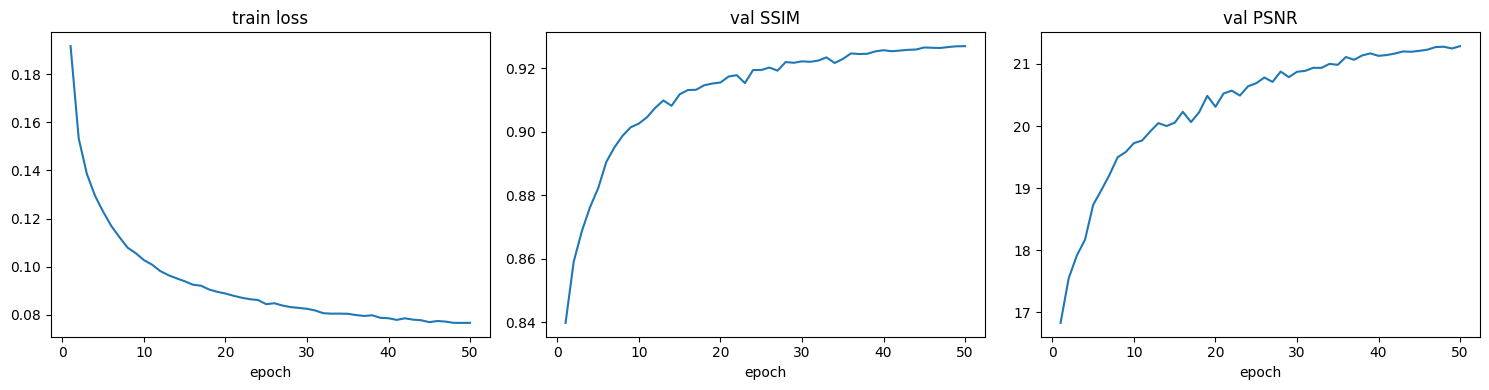

    epoch  train_loss  val_ssim  val_psnr
0       1      0.1917    0.8397   16.8303
9      10      0.1027    0.9026   19.7260
19     20      0.0888    0.9155   20.3106
29     30      0.0825    0.9222   20.8742
39     40      0.0785    0.9257   21.1311
49     50      0.0766    0.9270   21.2871


In [12]:
h = pd.read_csv(f"{OUT_DIR}/train_history.csv")
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(h.epoch, h.train_loss); ax[0].set_title("train loss")
ax[1].plot(h.epoch, h.val_ssim);   ax[1].set_title("val SSIM")
ax[2].plot(h.epoch, h.val_psnr);   ax[2].set_title("val PSNR")
for a in ax: a.set_xlabel("epoch")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/curves.png", dpi=150); plt.show()
print(h[["epoch", "train_loss", "val_ssim", "val_psnr"]].iloc[[0, 9, 19, 29, 39, -1]].round(4))

In [13]:
e = enhance_full(model, load_gray(val_pairs[0][0]))
print("min", e.min(), "max", e.max(), "mean", e.mean(), "std", e.std())

min 0.0 max 1.0 mean 0.5274541 std 0.3901129


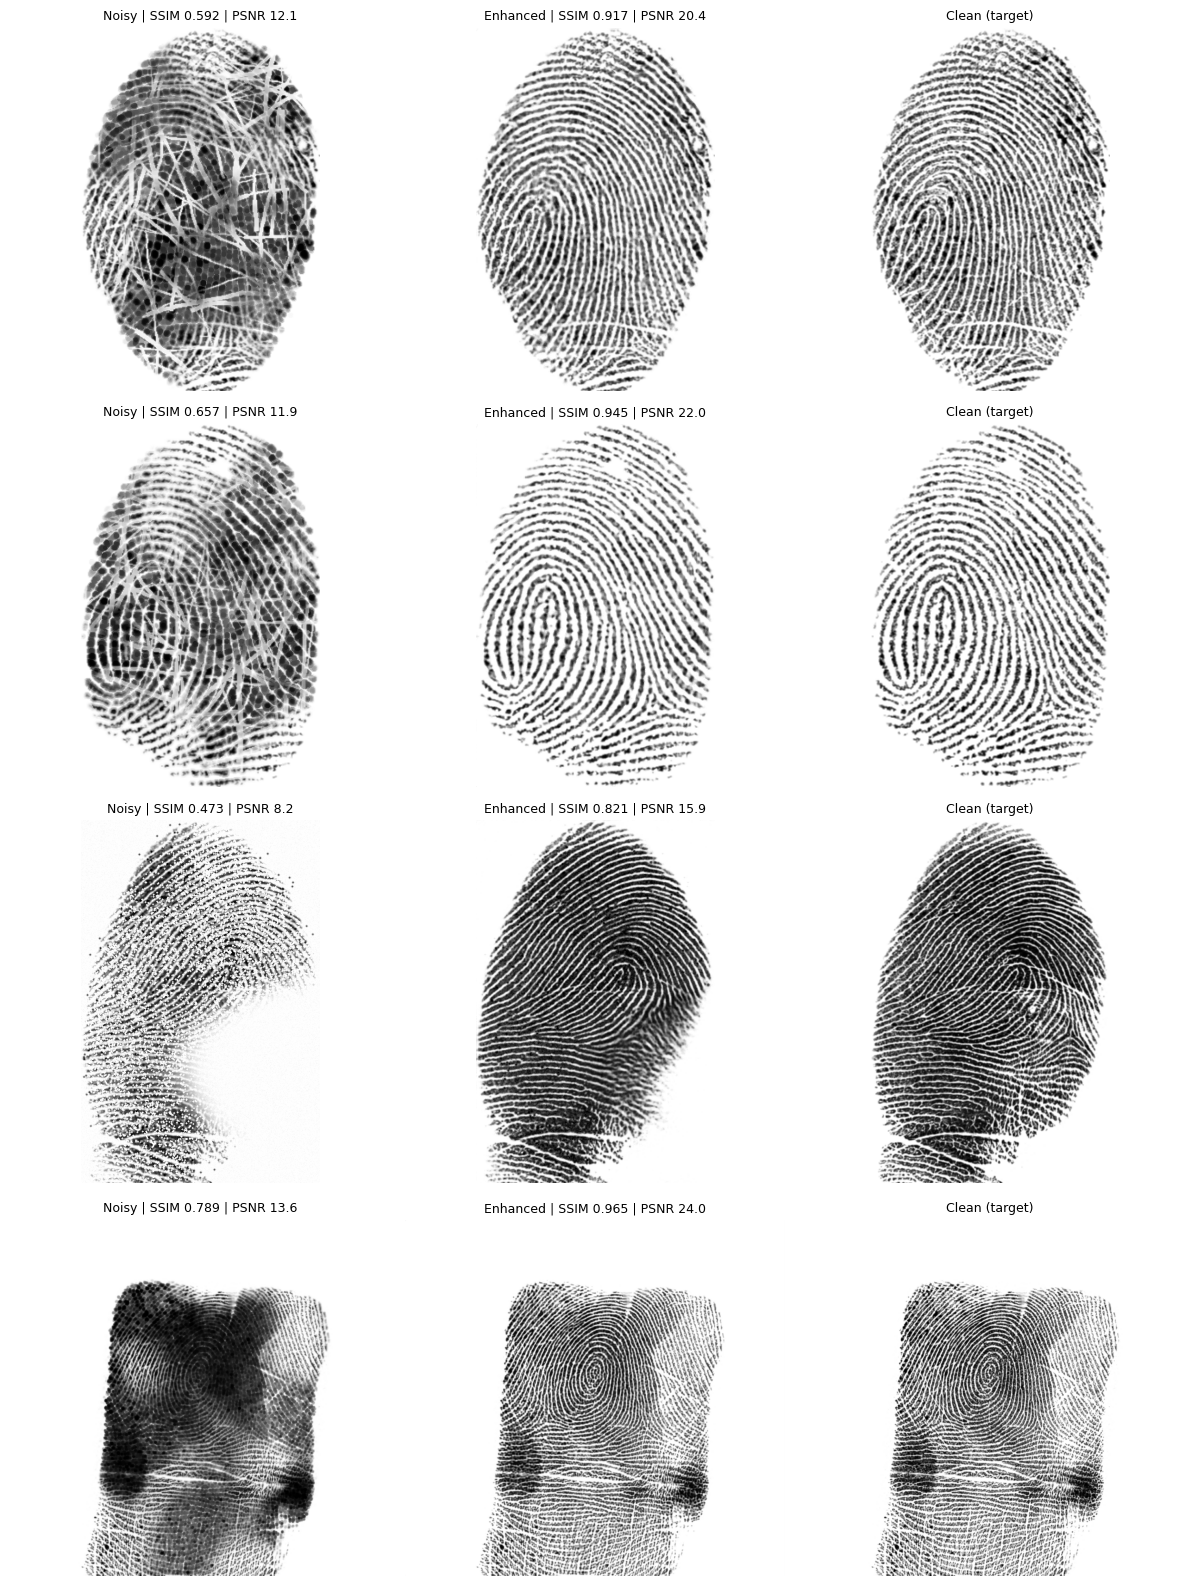

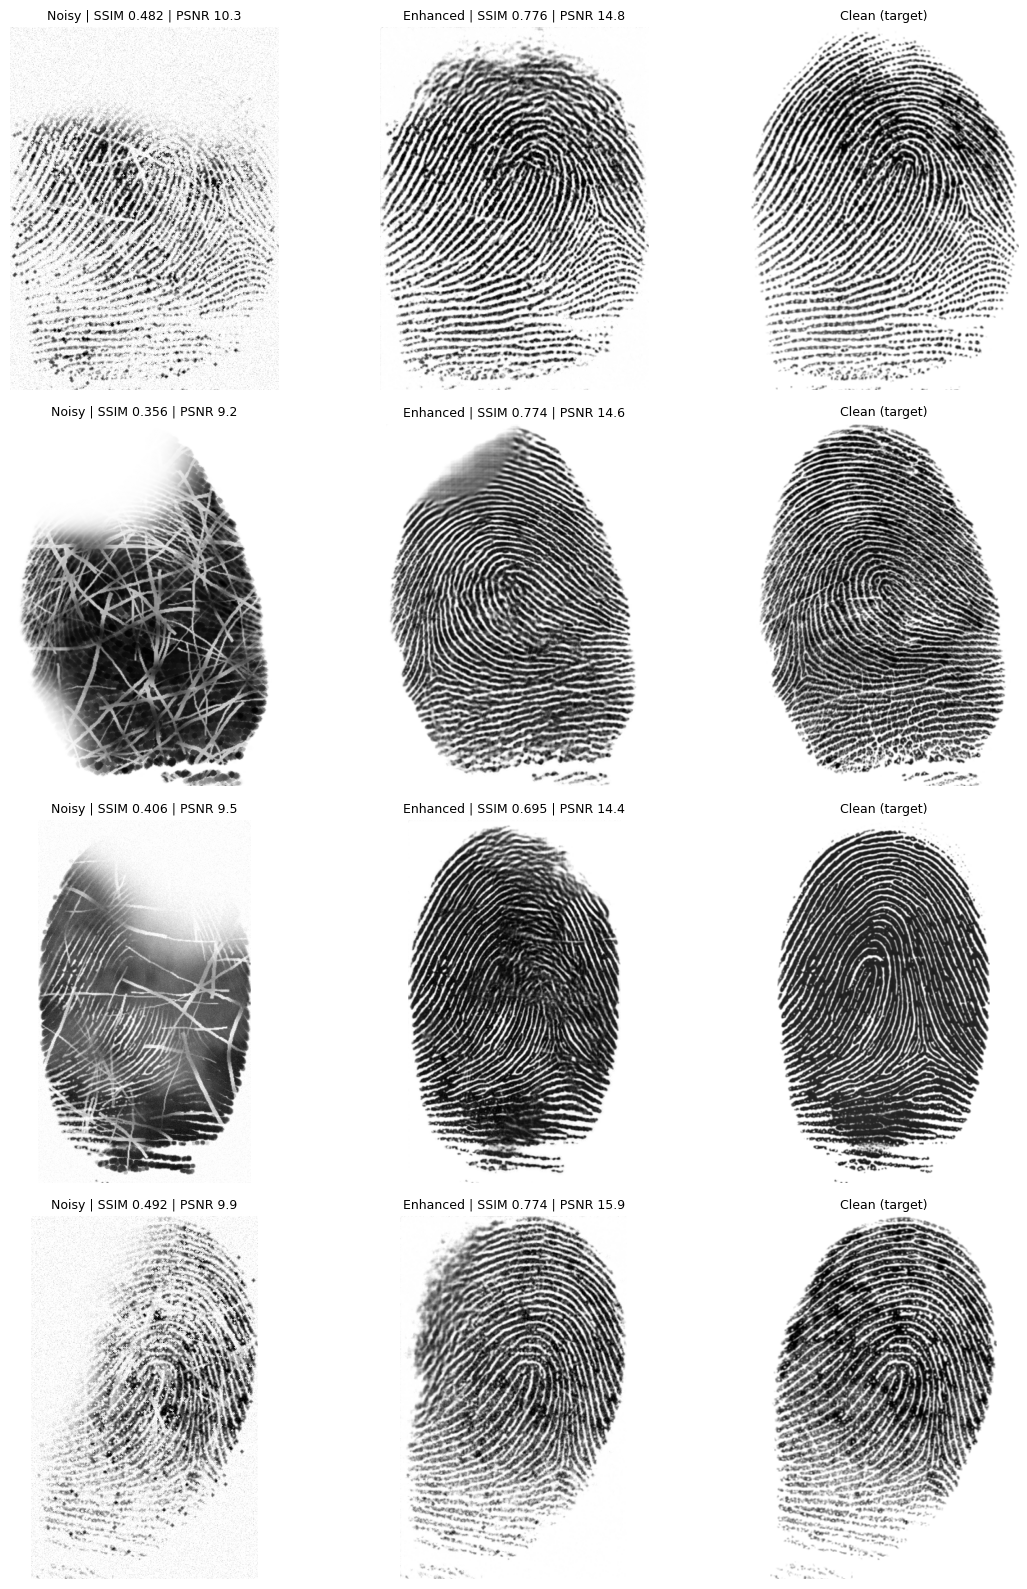

In [14]:
def show(df, n=4, save=f"{OUT_DIR}/visuals.png"):
    sel = df.sample(min(n, len(df)), random_state=1)
    fig, ax = plt.subplots(len(sel), 3, figsize=(12, 4 * len(sel)))
    ax = np.atleast_2d(ax)
    for i, (_, r) in enumerate(sel.iterrows()):
        x, c = load_gray(r.noisy), load_gray(r.clean)
        e = enhance_full(model, x)
        items = [(x, f"Noisy | SSIM {r.ssim_noisy:.3f} | PSNR {r.psnr_noisy:.1f}"),
                 (e, f"Enhanced | SSIM {r.ssim_enh:.3f} | PSNR {r.psnr_enh:.1f}"),
                 (c, "Clean (target)")]
        for j, (img, t) in enumerate(items):
            ax[i, j].imshow(img, cmap="gray", vmin=0, vmax=1); ax[i, j].set_title(t, fontsize=9); ax[i, j].axis("off")
    plt.tight_layout(); plt.savefig(save, dpi=150); plt.show()

show(res, n=4)                                                                      # random 4
show(res.sort_values("ssim_enh").head(4), n=4, save=f"{OUT_DIR}/visuals_worst.png")  # sabse kharab 4

In [15]:
import requests
rels = requests.get("https://api.github.com/repos/usnistgov/NFIQ2/releases", timeout=30).json()
for r in rels[:3]:
    print(r["tag_name"], "| prerelease:", r["prerelease"])
    for a in r["assets"]: print("   ", a["name"], "\n      ", a["browser_download_url"])

v2.3.0 | prerelease: False
    nfiq2-2.3.0-macos.pkg 
       https://github.com/usnistgov/NFIQ2/releases/download/v2.3.0/nfiq2-2.3.0-macos.pkg
    nfiq2-2.3.0-win32.msi 
       https://github.com/usnistgov/NFIQ2/releases/download/v2.3.0/nfiq2-2.3.0-win32.msi
    nfiq2-2.3.0-win64.msi 
       https://github.com/usnistgov/NFIQ2/releases/download/v2.3.0/nfiq2-2.3.0-win64.msi
    nfiq2-dev_2.3.0-1_rpos12_arm64.deb 
       https://github.com/usnistgov/NFIQ2/releases/download/v2.3.0/nfiq2-dev_2.3.0-1_rpos12_arm64.deb
    nfiq2-dev_2.3.0-1_ubuntu20_amd64.deb 
       https://github.com/usnistgov/NFIQ2/releases/download/v2.3.0/nfiq2-dev_2.3.0-1_ubuntu20_amd64.deb
    nfiq2-dev_2.3.0-1_ubuntu22_amd64.deb 
       https://github.com/usnistgov/NFIQ2/releases/download/v2.3.0/nfiq2-dev_2.3.0-1_ubuntu22_amd64.deb
    nfiq2-dev_2.3.0-1_ubuntu24_amd64.deb 
       https://github.com/usnistgov/NFIQ2/releases/download/v2.3.0/nfiq2-dev_2.3.0-1_ubuntu24_amd64.deb
    nfiq2_2.3.0-1_rpos12_arm64.deb 
       ht

In [16]:
# 1) Kaggle machine ka Ubuntu version dekho
osr = open("/etc/os-release").read()
print(osr[:300])
ver = re.search(r'VERSION_ID="?([\d.]+)', osr).group(1)           # jaise 22.04
tag = {"20.04": "ubuntu20", "22.04": "ubuntu22", "24.04": "ubuntu24"}.get(ver)
assert tag, f"Ubuntu {ver} ke liye v2.3.0 mein deb nahi dikha, mujhe os-release ka output bhejo"

# 2) us version ka nfiq2 (non-dev) deb download karo aur install karo
ASSET_URL = f"https://github.com/usnistgov/NFIQ2/releases/download/v2.3.0/nfiq2_2.3.0-1_{tag}_amd64.deb"
fn = f"/kaggle/working/{ASSET_URL.split('/')[-1]}"
subprocess.run(["wget", "-q", "-O", fn, ASSET_URL], check=True)
r = subprocess.run(["dpkg", "-i", fn], capture_output=True, text=True)
print(r.stdout[-800:], r.stderr[-800:])
if r.returncode != 0:                                              # dependencies adhoori hon to
    r2 = subprocess.run("apt-get install -f -y", shell=True, capture_output=True, text=True)
    print(r2.stdout[-800:], r2.stderr[-800:])

# 3) executable ka path
NFIQ2 = shutil.which("nfiq2")
print("NFIQ2 path:", NFIQ2)
print(subprocess.run(["nfiq2", "--help"], capture_output=True, text=True).stdout[:1200])

PRETTY_NAME="Ubuntu 24.04.1 LTS"
NAME="Ubuntu"
VERSION_ID="24.04"
VERSION="24.04.1 LTS (Noble Numbat)"
VERSION_CODENAME=noble
ID=ubuntu
ID_LIKE=debian
HOME_URL="https://www.ubuntu.com/"
SUPPORT_URL="https://help.ubuntu.com/"
BUG_REPORT_URL="https://bugs.launchpad.net/ubuntu/"
PRIVACY_POLICY_URL="htt
Selecting previously unselected package nfiq2.
(Reading database ... 129796 files and directories currently installed.)
Preparing to unpack .../nfiq2_2.3.0-1_ubuntu24_amd64.deb ...
Unpacking nfiq2 (2.3.0-1) ...
 dpkg: dependency problems prevent configuration of nfiq2:
 nfiq2 depends on libdb5.3++t64; however:
  Package libdb5.3++t64 is not installed.

dpkg: error processing package nfiq2 (--install):
 dependency problems - leaving unconfigured
Errors were encountered while processing:
 nfiq2

k

/sbin/ldconfig.real: /usr/local/lib/libur_adapter_level_zero_v2.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbbind_2_0.so.3 is not a symbolic link

/sbin/ldconfig.real: /us

In [17]:
NFIQ2 = shutil.which("nfiq2")          # Cell 10 se mila path
print(subprocess.run([NFIQ2, "--help"], capture_output=True, text=True).stdout[:1500])

sub = res.sample(min(100, len(res)), random_state=SEED)   # test ke 100 random pairs
dirs = {k: f"/kaggle/working/nfiq_tmp/{k}" for k in ["noisy", "enhanced", "clean"]}
for d in dirs.values(): os.makedirs(d, exist_ok=True)
for _, r in sub.iterrows():
    name = os.path.splitext(os.path.basename(r.noisy))[0] + ".png"     # teeno folders mein same naam
    shutil.copy(r.noisy, f"{dirs['noisy']}/{name}")
    shutil.copy(r.clean, f"{dirs['clean']}/{name}")
    e = enhance_full(model, load_gray(r.noisy))
    Image.fromarray((e * 255).round().astype(np.uint8)).save(f"{dirs['enhanced']}/{name}", dpi=(500, 500))

def run_nfiq2(img_dir):
    out_csv = f"{img_dir}.csv"
    p = subprocess.run([NFIQ2, "-i", img_dir, "-o", out_csv], capture_output=True, text=True)
    if p.returncode != 0: print(p.stdout[-800:], p.stderr[-800:])
    df = pd.read_csv(out_csv); print(os.path.basename(img_dir), "columns:", df.columns.tolist())
    fcol = next(c for c in df.columns if "file" in c.lower() or "name" in c.lower())
    qcol = next(c for c in df.columns if "quality" in c.lower())
    return pd.DataFrame({"name": df[fcol].astype(str).map(os.path.basename),
                         "score": pd.to_numeric(df[qcol], errors="coerce")})

sc = {k: run_nfiq2(d) for k, d in dirs.items()}
nf = sc["noisy"].merge(sc["enhanced"], on="name", suffixes=("_noisy", "_enhanced")) \
                .merge(sc["clean"].rename(columns={"score": "score_clean"}), on="name")
nf.to_csv(f"{OUT_DIR}/nfiq2_scores.csv", index=False)
print("fail hue (NaN):", nf.isna().sum().to_dict())
print(nf[["score_noisy", "score_enhanced", "score_clean"]].describe().loc[["count", "mean"]].round(2))


                               Welcome to NFIQ2

      Please provide individual files or directories to the command line.
            If you would like to use one of the flags listed below,
              please include them before any standard arguments.

Currently implemented flags and their functions: 
-i [file/directory path]: Processing provided Images and Directories
-f [batch file path]: Processing provided batch files
-o [file path]: Saving all output to a specified file
-j [# of threads]: Enables Multi-Threading for Batch and RecordStore processes
-m [model info file]: Path to alternate model info file 
-a: Displays actionable quality scores about each processed image
-v: Displays individual quality score information about each processed image
-b: Displays native quality measure values mapped for 39794-2 quality blocks
-q: Displays individual quality speed timings about each processed image
-d: Displays additional debug information as each score gets computed
-F: Forces compu

In [18]:

import os
import shutil
import subprocess
import glob

NFIQ2 = shutil.which("nfiq2")
print("NFIQ2 executable:", NFIQ2)

if NFIQ2:
    p = subprocess.run(
        [NFIQ2, "--help"],
        capture_output=True,
        text=True
    )
    print("Help output:")
    print((p.stdout + "\n" + p.stderr)[:2000])

for k, d in dirs.items():
    files = glob.glob(os.path.join(d, "*"))
    print(f"\n{k}: {len(files)} files")
    print("Directory:", d)
    print("Sample:", files[:3])

    if files:
        p = subprocess.run(
            [NFIQ2, "-i", files[0]],
            capture_output=True,
            text=True
        )
        print("Single-image return code:", p.returncode)
        print("STDOUT:", p.stdout[-1000:])
        print("STDERR:", p.stderr[-1000:])


NFIQ2 executable: /usr/local/bin/nfiq2
Help output:

                               Welcome to NFIQ2

      Please provide individual files or directories to the command line.
            If you would like to use one of the flags listed below,
              please include them before any standard arguments.

Currently implemented flags and their functions: 
-i [file/directory path]: Processing provided Images and Directories
-f [batch file path]: Processing provided batch files
-o [file path]: Saving all output to a specified file
-j [# of threads]: Enables Multi-Threading for Batch and RecordStore processes
-m [model info file]: Path to alternate model info file 
-a: Displays actionable quality scores about each processed image
-v: Displays individual quality score information about each processed image
-b: Displays native quality measure values mapped for 39794-2 quality blocks
-q: Displays individual quality speed timings about each processed image
-d: Displays additional debug info

In [19]:

from PIL import Image
import os
import glob
import subprocess
import pandas as pd

# Set 500 PPI metadata for all three groups
for k in ["noisy", "enhanced", "clean"]:
    img_dir = dirs[k]
    count = 0

    for path in glob.glob(os.path.join(img_dir, "*.png")):
        with Image.open(path) as im:
            im.load()
            im.save(path, format="PNG", dpi=(500, 500))
        count += 1

    print(f"{k}: updated {count} images")

# Verify metadata
for k in ["noisy", "enhanced", "clean"]:
    path = glob.glob(os.path.join(dirs[k], "*.png"))[0]
    with Image.open(path) as im:
        print(k, "size:", im.size, "| DPI:", im.info.get("dpi"))


noisy: updated 100 images
enhanced: updated 100 images
clean: updated 100 images
noisy size: (325, 529) | DPI: (499.99899999999997, 499.99899999999997)
enhanced size: (325, 529) | DPI: (499.99899999999997, 499.99899999999997)
clean size: (325, 529) | DPI: (499.99899999999997, 499.99899999999997)


In [20]:

def run_nfiq2_fixed(img_dir):
    out_csv = f"{img_dir}_fixed.csv"

    p = subprocess.run(
        [NFIQ2, "-F", "-i", img_dir, "-o", out_csv],
        capture_output=True,
        text=True
    )

    print(f"\nFolder: {os.path.basename(img_dir)}")
    print("Return code:", p.returncode)

    if p.stdout:
        print("Output:", p.stdout[-1000:])
    if p.stderr:
        print("Errors:", p.stderr[-1000:])

    if not os.path.exists(out_csv):
        raise FileNotFoundError(f"NFIQ2 did not create {out_csv}")

    df = pd.read_csv(out_csv)
    print("Columns:", df.columns.tolist())

    fcol = next(
        c for c in df.columns
        if "file" in c.lower() or "name" in c.lower()
    )
    qcol = next(
        c for c in df.columns
        if "quality" in c.lower()
    )

    return pd.DataFrame({
        "name": df[fcol].astype(str).map(os.path.basename),
        "score": pd.to_numeric(df[qcol], errors="coerce")
    })

sc = {
    k: run_nfiq2_fixed(dirs[k])
    for k in ["noisy", "enhanced", "clean"]
}

print("\nValid scores:")
for k, df in sc.items():
    print(k, df["score"].notna().sum(), "/", len(df))



Folder: noisy
Return code: 0
Columns: ['Filename', 'FingerCode', 'QualityScore', 'OptionalError', 'Quantized', 'Resampled']

Folder: enhanced
Return code: 0
Columns: ['Filename', 'FingerCode', 'QualityScore', 'OptionalError', 'Quantized', 'Resampled']

Folder: clean
Return code: 0
Columns: ['Filename', 'FingerCode', 'QualityScore', 'OptionalError', 'Quantized', 'Resampled']

Valid scores:
noisy 100 / 100
enhanced 100 / 100
clean 100 / 100


In [22]:

# Positive delta means NFIQ2 quality improved
nf["delta"] = nf["score_enhanced"] - nf["score_noisy"]

nf["improved"] = nf["delta"] > 0
nf["unchanged"] = nf["delta"] == 0
nf["declined"] = nf["delta"] < 0

print("Matched images:", len(nf))
print("Mean noisy:", round(nf["score_noisy"].mean(), 2))
print("Mean enhanced:", round(nf["score_enhanced"].mean(), 2))
print("Mean clean:", round(nf["score_clean"].mean(), 2))
print("Mean improvement:", round(nf["delta"].mean(), 2))

print("Improved:", int(nf["improved"].sum()))
print("Unchanged:", int(nf["unchanged"].sum()))
print("Declined:", int(nf["declined"].sum()))

print("Improvement rate (%):",
      round(100 * nf["improved"].mean(), 2))


Matched images: 100
Mean noisy: 20.63
Mean enhanced: 73.46
Mean clean: 72.19
Mean improvement: 52.83
Improved: 100
Unchanged: 0
Declined: 0
Improvement rate (%): 100.0


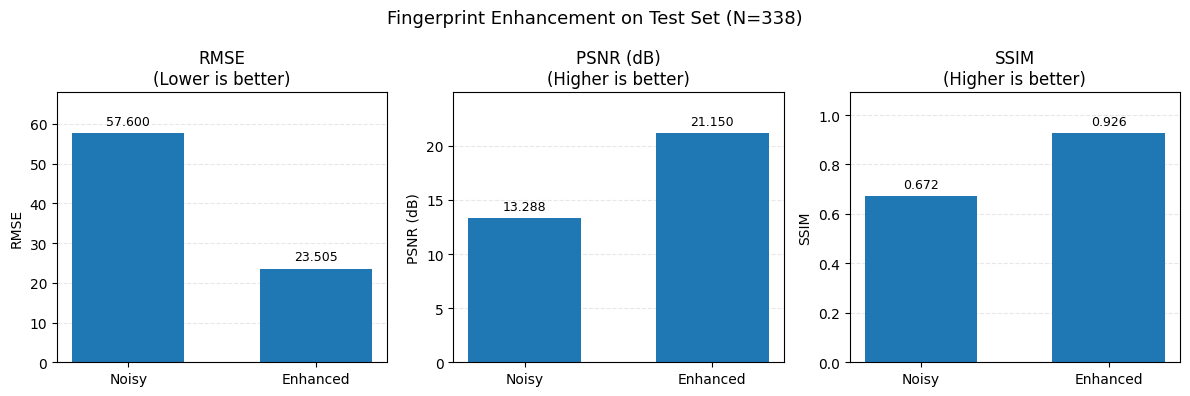

Actual test-set means:
rmse_noisy    57.5999
rmse_enh      23.5052
psnr_noisy    13.2875
psnr_enh      21.1501
ssim_noisy     0.6716
ssim_enh       0.9259
dtype: float64


In [23]:

# FIGURE 1: Overall test-set metric comparison
# Data source: Cell 10 -> res

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# If res is not in memory, load the actual saved test results
if "res" not in globals():
    res = pd.read_csv(f"{OUT_DIR}/test_metrics.csv")

# Calculate means directly from all evaluated test images
metric_pairs = [
    ("rmse_noisy", "rmse_enh", "RMSE", "Lower is better"),
    ("psnr_noisy", "psnr_enh", "PSNR (dB)", "Higher is better"),
    ("ssim_noisy", "ssim_enh", "SSIM", "Higher is better")
]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, (before_col, after_col, title, note) in zip(
    axes, metric_pairs
):
    values = res[[before_col, after_col]].mean()

    labels = ["Noisy", "Enhanced"]
    scores = [values[before_col], values[after_col]]

    bars = ax.bar(labels, scores, width=0.6)
    ax.bar_label(bars, fmt="%.3f", padding=4, fontsize=9)

    ax.set_title(f"{title}\n({note})")
    ax.set_ylabel(title)
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.set_axisbelow(True)
    ax.margins(y=0.18)

fig.suptitle(
    f"Fingerprint Enhancement on Test Set (N={len(res)})",
    fontsize=13
)

plt.tight_layout()

# Save publication-quality figures
os.makedirs(OUT_DIR, exist_ok=True)

fig.savefig(
    f"{OUT_DIR}/fig1_overall_comparison.png",
    dpi=300, bbox_inches="tight"
)
fig.savefig(
    f"{OUT_DIR}/fig1_overall_comparison.pdf",
    bbox_inches="tight"
)

plt.show()

print("Actual test-set means:")
print(
    res[[
        "rmse_noisy", "rmse_enh",
        "psnr_noisy", "psnr_enh",
        "ssim_noisy", "ssim_enh"
    ]].mean().round(4)
)


Actual device-wise mean results:


,rmse_noisy,rmse_enh,psnr_noisy,psnr_enh,ssim_noisy,ssim_enh
device,,,,,,
R,72.4453,29.7240,11.0909,18.9472,0.5578,0.8865
S,66.6895,26.6462,11.9060,19.9491,0.5864,0.9007
U,48.0033,19.9589,14.7277,22.4384,0.7665,0.9506
V,48.4885,19.8456,14.6517,22.5068,0.7319,0.9524


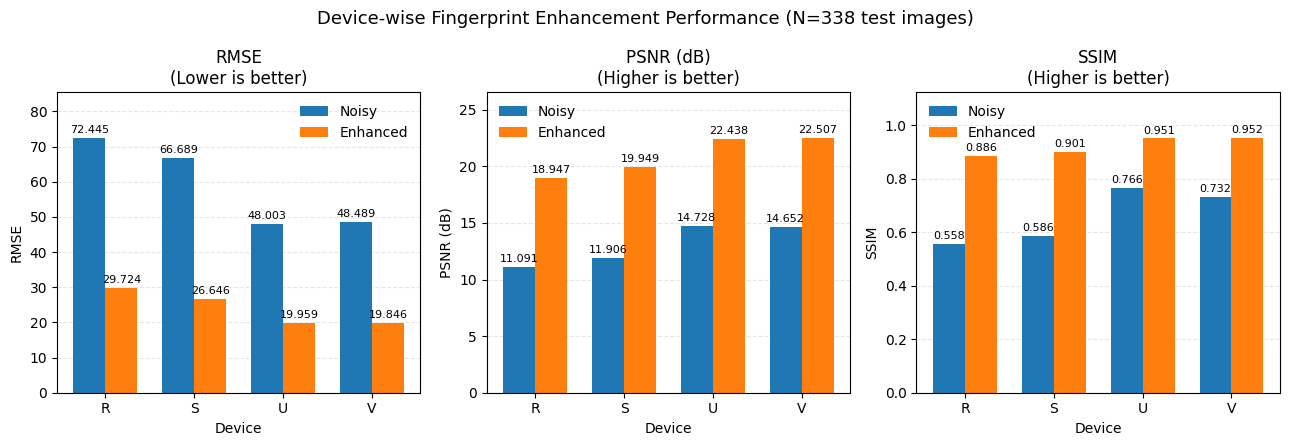

Saved:
/kaggle/working/lfrnet_out_official/fig2_device_wise_comparison.png
/kaggle/working/lfrnet_out_official/fig2_device_wise_comparison.pdf


In [24]:

# FIGURE 2: Device-wise fingerprint enhancement comparison
# Automatically uses the actual test results from Cell 10

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load actual evaluation results if res is not available
if "res" not in globals():
    res = pd.read_csv(f"{OUT_DIR}/test_metrics.csv")

# Check required columns
required = [
    "device",
    "rmse_noisy", "rmse_enh",
    "psnr_noisy", "psnr_enh",
    "ssim_noisy", "ssim_enh"
]

missing = [c for c in required if c not in res.columns]
if missing:
    raise ValueError(f"Missing columns in test results: {missing}")

# Calculate actual mean metrics for each device
device_results = (
    res.groupby("device", dropna=False)[
        required[1:]
    ]
    .mean()
    .sort_index()
)

print("Actual device-wise mean results:")
display(device_results.round(4))

# Plot each metric in a separate panel
plot_config = [
    ("rmse_noisy", "rmse_enh", "RMSE", "Lower is better"),
    ("psnr_noisy", "psnr_enh", "PSNR (dB)", "Higher is better"),
    ("ssim_noisy", "ssim_enh", "SSIM", "Higher is better")
]

devices = device_results.index.astype(str)
x = np.arange(len(devices))
width = 0.36

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))

for ax, (before, after, title, note) in zip(
    axes, plot_config
):
    noisy_values = device_results[before].values
    enhanced_values = device_results[after].values

    b1 = ax.bar(
        x - width / 2, noisy_values,
        width, label="Noisy"
    )
    b2 = ax.bar(
        x + width / 2, enhanced_values,
        width, label="Enhanced"
    )

    ax.set_title(f"{title}\n({note})")
    ax.set_ylabel(title)
    ax.set_xticks(x)
    ax.set_xticklabels(devices)
    ax.set_xlabel("Device")
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.set_axisbelow(True)
    ax.legend(frameon=False)

    # Display measured values automatically
    ax.bar_label(b1, fmt="%.3f", padding=2, fontsize=8)
    ax.bar_label(b2, fmt="%.3f", padding=2, fontsize=8)
    ax.margins(y=0.18)

fig.suptitle(
    f"Device-wise Fingerprint Enhancement Performance "
    f"(N={len(res)} test images)",
    fontsize=13
)

plt.tight_layout()

# Save in publication-ready formats
os.makedirs(OUT_DIR, exist_ok=True)

fig.savefig(
    f"{OUT_DIR}/fig2_device_wise_comparison.png",
    dpi=300, bbox_inches="tight"
)
fig.savefig(
    f"{OUT_DIR}/fig2_device_wise_comparison.pdf",
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(f"{OUT_DIR}/fig2_device_wise_comparison.png")
print(f"{OUT_DIR}/fig2_device_wise_comparison.pdf")


Per-device improvement from test results:


,RMSE reduction (%),PSNR gain (dB),SSIM gain
device,,,
R,58.9704,7.8563,0.3287
S,60.0444,8.0431,0.3144
U,58.4219,7.7107,0.1841
V,59.0715,7.8551,0.2204


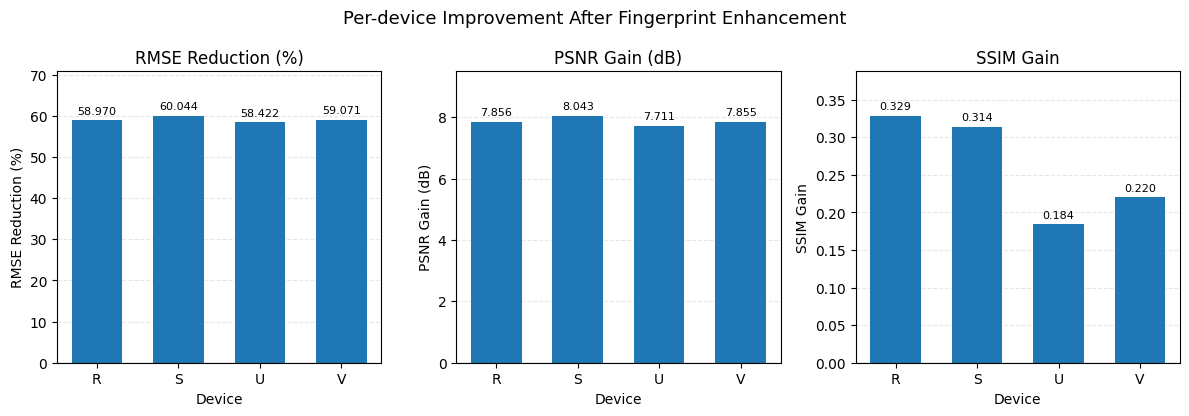

Saved files:
/kaggle/working/lfrnet_out_official/fig3_device_improvement.png
/kaggle/working/lfrnet_out_official/fig3_device_improvement.pdf
/kaggle/working/lfrnet_out_official/fig3_device_improvement_data.csv


In [25]:

# FIGURE 3: Per-device improvement after fingerprint enhancement
# Uses actual per-image test results; no manually entered metric values.

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use the results already calculated in Cell 10
if "res" not in globals():
    res = pd.read_csv(f"{OUT_DIR}/test_metrics.csv")

required = [
    "device",
    "rmse_noisy", "rmse_enh",
    "psnr_noisy", "psnr_enh",
    "ssim_noisy", "ssim_enh"
]

missing = [c for c in required if c not in res.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

# Calculate device-wise means from the actual test set
device_results = (
    res.groupby("device")[required[1:]]
    .mean()
    .sort_index()
)

# Calculate improvement metrics
device_results["RMSE reduction (%)"] = (
    (device_results["rmse_noisy"] - device_results["rmse_enh"])
    / device_results["rmse_noisy"].replace(0, np.nan)
) * 100

device_results["PSNR gain (dB)"] = (
    device_results["psnr_enh"] - device_results["psnr_noisy"]
)

device_results["SSIM gain"] = (
    device_results["ssim_enh"] - device_results["ssim_noisy"]
)

# Display the actual calculated values
print("Per-device improvement from test results:")
display(
    device_results[
        ["RMSE reduction (%)", "PSNR gain (dB)", "SSIM gain"]
    ].round(4)
)

# Create publication-quality plots
plot_columns = [
    ("RMSE reduction (%)", "RMSE Reduction (%)"),
    ("PSNR gain (dB)", "PSNR Gain (dB)"),
    ("SSIM gain", "SSIM Gain")
]

fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
devices = device_results.index.astype(str)

for ax, (column, title) in zip(axes, plot_columns):
    values = device_results[column].values
    bars = ax.bar(devices, values, width=0.62)

    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=8)
    ax.set_title(title)
    ax.set_xlabel("Device")
    ax.set_ylabel(title)
    ax.axhline(0, linewidth=0.8)
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.set_axisbelow(True)
    ax.margins(y=0.18)

fig.suptitle(
    "Per-device Improvement After Fingerprint Enhancement",
    fontsize=13
)

plt.tight_layout()

# Save figures and calculated data
os.makedirs(OUT_DIR, exist_ok=True)

fig.savefig(
    f"{OUT_DIR}/fig3_device_improvement.png",
    dpi=300,
    bbox_inches="tight"
)
fig.savefig(
    f"{OUT_DIR}/fig3_device_improvement.pdf",
    bbox_inches="tight"
)

device_results.to_csv(
    f"{OUT_DIR}/fig3_device_improvement_data.csv"
)

plt.show()

print("Saved files:")
print(f"{OUT_DIR}/fig3_device_improvement.png")
print(f"{OUT_DIR}/fig3_device_improvement.pdf")
print(f"{OUT_DIR}/fig3_device_improvement_data.csv")


History columns: ['epoch', 'train_loss', 'val_rmse', 'val_psnr', 'val_ssim', 'sec']
Total recorded epochs: 50


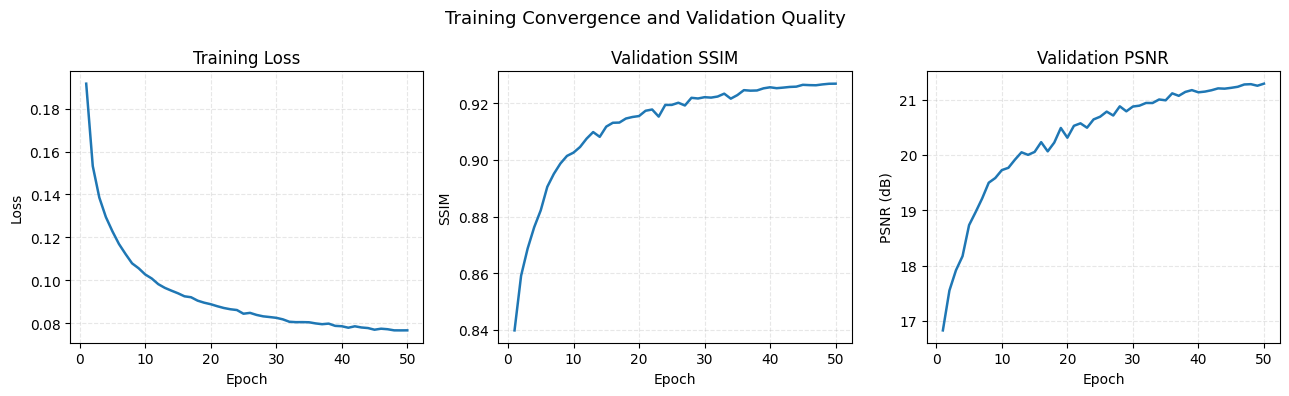

Saved:
/kaggle/working/lfrnet_out_official/fig4_training_history.png
/kaggle/working/lfrnet_out_official/fig4_training_history.pdf

Last recorded training values:


,epoch,train_loss,val_rmse,val_psnr,val_ssim,sec
45,46,0.077388,23.226303,21.230766,0.926457,163.199682
46,47,0.077140,23.124787,21.272621,0.926410,163.207558
47,48,0.076619,23.076070,21.278127,0.926714,163.091394
48,49,0.076602,23.149764,21.249816,0.926939,163.131847
49,50,0.076624,23.059789,21.287133,0.926973,162.796398


In [26]:

# FIGURE 4: Training convergence and validation performance
# Automatically reads the actual training history from the notebook.

import os
import pandas as pd
import matplotlib.pyplot as plt

# Locate the actual training history
history_path = os.path.join(OUT_DIR, "train_history.csv")

if not os.path.exists(history_path):
    raise FileNotFoundError(
        f"Training history not found: {history_path}\n"
        "Check the path where your training history was saved."
    )

history = pd.read_csv(history_path)

print("History columns:", history.columns.tolist())
print("Total recorded epochs:", len(history))

# Match common column-name variations
def find_column(candidates, columns):
    lookup = {c.lower().strip(): c for c in columns}
    for candidate in candidates:
        if candidate.lower() in lookup:
            return lookup[candidate.lower()]
    return None

epoch_col = find_column(
    ["epoch", "epochs"], history.columns
)
loss_col = find_column(
    ["train_loss", "training_loss", "loss"], history.columns
)
ssim_col = find_column(
    ["val_ssim", "val_ssim_m", "validation_ssim"], history.columns
)
psnr_col = find_column(
    ["val_psnr", "val_psnr_m", "validation_psnr"], history.columns
)

if loss_col is None or ssim_col is None or psnr_col is None:
    raise ValueError(
        "Could not identify all required columns.\n"
        f"Available columns: {history.columns.tolist()}"
    )

# Use the epoch column if present; otherwise use row order
if epoch_col is not None:
    epochs = pd.to_numeric(history[epoch_col], errors="coerce")
else:
    epochs = pd.Series(range(1, len(history) + 1))

# Plot actual values
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

plots = [
    (loss_col, "Training Loss", "Loss"),
    (ssim_col, "Validation SSIM", "SSIM"),
    (psnr_col, "Validation PSNR", "PSNR (dB)")
]

for ax, (column, title, ylabel) in zip(axes, plots):
    y = pd.to_numeric(history[column], errors="coerce")
    valid = epochs.notna() & y.notna()

    ax.plot(
        epochs[valid],
        y[valid],
        linewidth=1.8
    )

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.grid(True, linestyle="--", alpha=0.3)

fig.suptitle(
    "Training Convergence and Validation Quality",
    fontsize=13
)

plt.tight_layout()

# Save publication-ready figures
os.makedirs(OUT_DIR, exist_ok=True)

fig.savefig(
    f"{OUT_DIR}/fig4_training_history.png",
    dpi=300,
    bbox_inches="tight"
)
fig.savefig(
    f"{OUT_DIR}/fig4_training_history.pdf",
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(f"{OUT_DIR}/fig4_training_history.png")
print(f"{OUT_DIR}/fig4_training_history.pdf")

# Show the final recorded values for verification
print("\nLast recorded training values:")
display(history.tail())


In [32]:

import os
import glob

BASE = "/kaggle/working/nfiq_tmp"

for folder in ["noisy", "clean", "enhanced"]:
    path = os.path.join(BASE, folder)
    print(f"\n--- {folder.upper()} ---")
    print("Folder exists:", os.path.isdir(path))

    if os.path.isdir(path):
        files = []
        for ext in ("*.png", "*.jpg", "*.jpeg", "*.bmp", "*.tif", "*.tiff"):
            files.extend(glob.glob(os.path.join(path, "**", ext), recursive=True))

        print("Image count:", len(files))
        for f in sorted(files)[:5]:
            print(" ", f)



--- NOISY ---
Folder exists: True
Image count: 100
  /kaggle/working/nfiq_tmp/noisy/00002303_U_500_roll_02.png
  /kaggle/working/nfiq_tmp/noisy/00002303_V_500_roll_07.png
  /kaggle/working/nfiq_tmp/noisy/00002325_R_500_slap_01.png
  /kaggle/working/nfiq_tmp/noisy/00002332_R_500_slap_02.png
  /kaggle/working/nfiq_tmp/noisy/00002332_R_500_slap_07.png

--- CLEAN ---
Folder exists: True
Image count: 100
  /kaggle/working/nfiq_tmp/clean/00002303_U_500_roll_02.png
  /kaggle/working/nfiq_tmp/clean/00002303_V_500_roll_07.png
  /kaggle/working/nfiq_tmp/clean/00002325_R_500_slap_01.png
  /kaggle/working/nfiq_tmp/clean/00002332_R_500_slap_02.png
  /kaggle/working/nfiq_tmp/clean/00002332_R_500_slap_07.png

--- ENHANCED ---
Folder exists: True
Image count: 100
  /kaggle/working/nfiq_tmp/enhanced/00002303_U_500_roll_02.png
  /kaggle/working/nfiq_tmp/enhanced/00002303_V_500_roll_07.png
  /kaggle/working/nfiq_tmp/enhanced/00002325_R_500_slap_01.png
  /kaggle/working/nfiq_tmp/enhanced/00002332_R_500_s

In [33]:

import pandas as pd
import os

BASE = "/kaggle/working/nfiq_tmp"

for name in [
    "noisy.csv",
    "clean.csv",
    "enhanced.csv",
    "noisy_fixed.csv",
    "clean_fixed.csv",
    "enhanced_fixed.csv",
]:
    path = os.path.join(BASE, name)

    if os.path.isfile(path):
        df = pd.read_csv(path)
        print(f"\n--- {name} ---")
        print("Columns:", df.columns.tolist())
        display(df.head(3))



--- noisy.csv ---
Columns: ['Filename', 'FingerCode', 'QualityScore', 'OptionalError', 'Quantized', 'Resampled']


,Filename,FingerCode,QualityScore,OptionalError,Quantized,Resampled
0,/kaggle/working/nfiq_tmp/noisy/00002557_S_500_...,0,NaN,Error: User chose not to re-sample image,0,0
1,/kaggle/working/nfiq_tmp/noisy/00002472_U_500_...,0,NaN,Error: User chose not to re-sample image,0,0
2,/kaggle/working/nfiq_tmp/noisy/00002555_S_500_...,0,NaN,Error: User chose not to re-sample image,0,0



--- clean.csv ---
Columns: ['Filename', 'FingerCode', 'QualityScore', 'OptionalError', 'Quantized', 'Resampled']


,Filename,FingerCode,QualityScore,OptionalError,Quantized,Resampled
0,/kaggle/working/nfiq_tmp/clean/00002557_S_500_...,0,82,NaN,0,0
1,/kaggle/working/nfiq_tmp/clean/00002472_U_500_...,0,87,NaN,0,0
2,/kaggle/working/nfiq_tmp/clean/00002555_S_500_...,0,64,NaN,0,0



--- enhanced.csv ---
Columns: ['Filename', 'FingerCode', 'QualityScore', 'OptionalError', 'Quantized', 'Resampled']


,Filename,FingerCode,QualityScore,OptionalError,Quantized,Resampled
0,/kaggle/working/nfiq_tmp/enhanced/00002557_S_5...,0,90,NaN,0,0
1,/kaggle/working/nfiq_tmp/enhanced/00002472_U_5...,0,78,NaN,0,0
2,/kaggle/working/nfiq_tmp/enhanced/00002555_S_5...,0,56,NaN,0,0


... (2 outputs left out)


--- clean_fixed.csv ---
Columns: ['Filename', 'FingerCode', 'QualityScore', 'OptionalError', 'Quantized', 'Resampled']


,Filename,FingerCode,QualityScore,OptionalError,Quantized,Resampled
0,/kaggle/working/nfiq_tmp/clean/00002557_S_500_...,0,82,NaN,0,0
1,/kaggle/working/nfiq_tmp/clean/00002472_U_500_...,0,87,NaN,0,0
2,/kaggle/working/nfiq_tmp/clean/00002555_S_500_...,0,64,NaN,0,0



--- enhanced_fixed.csv ---
Columns: ['Filename', 'FingerCode', 'QualityScore', 'OptionalError', 'Quantized', 'Resampled']


,Filename,FingerCode,QualityScore,OptionalError,Quantized,Resampled
0,/kaggle/working/nfiq_tmp/enhanced/00002557_S_5...,0,90,NaN,0,0
1,/kaggle/working/nfiq_tmp/enhanced/00002472_U_5...,0,78,NaN,0,0
2,/kaggle/working/nfiq_tmp/enhanced/00002555_S_5...,0,56,NaN,0,0


Matched fingerprints: 100


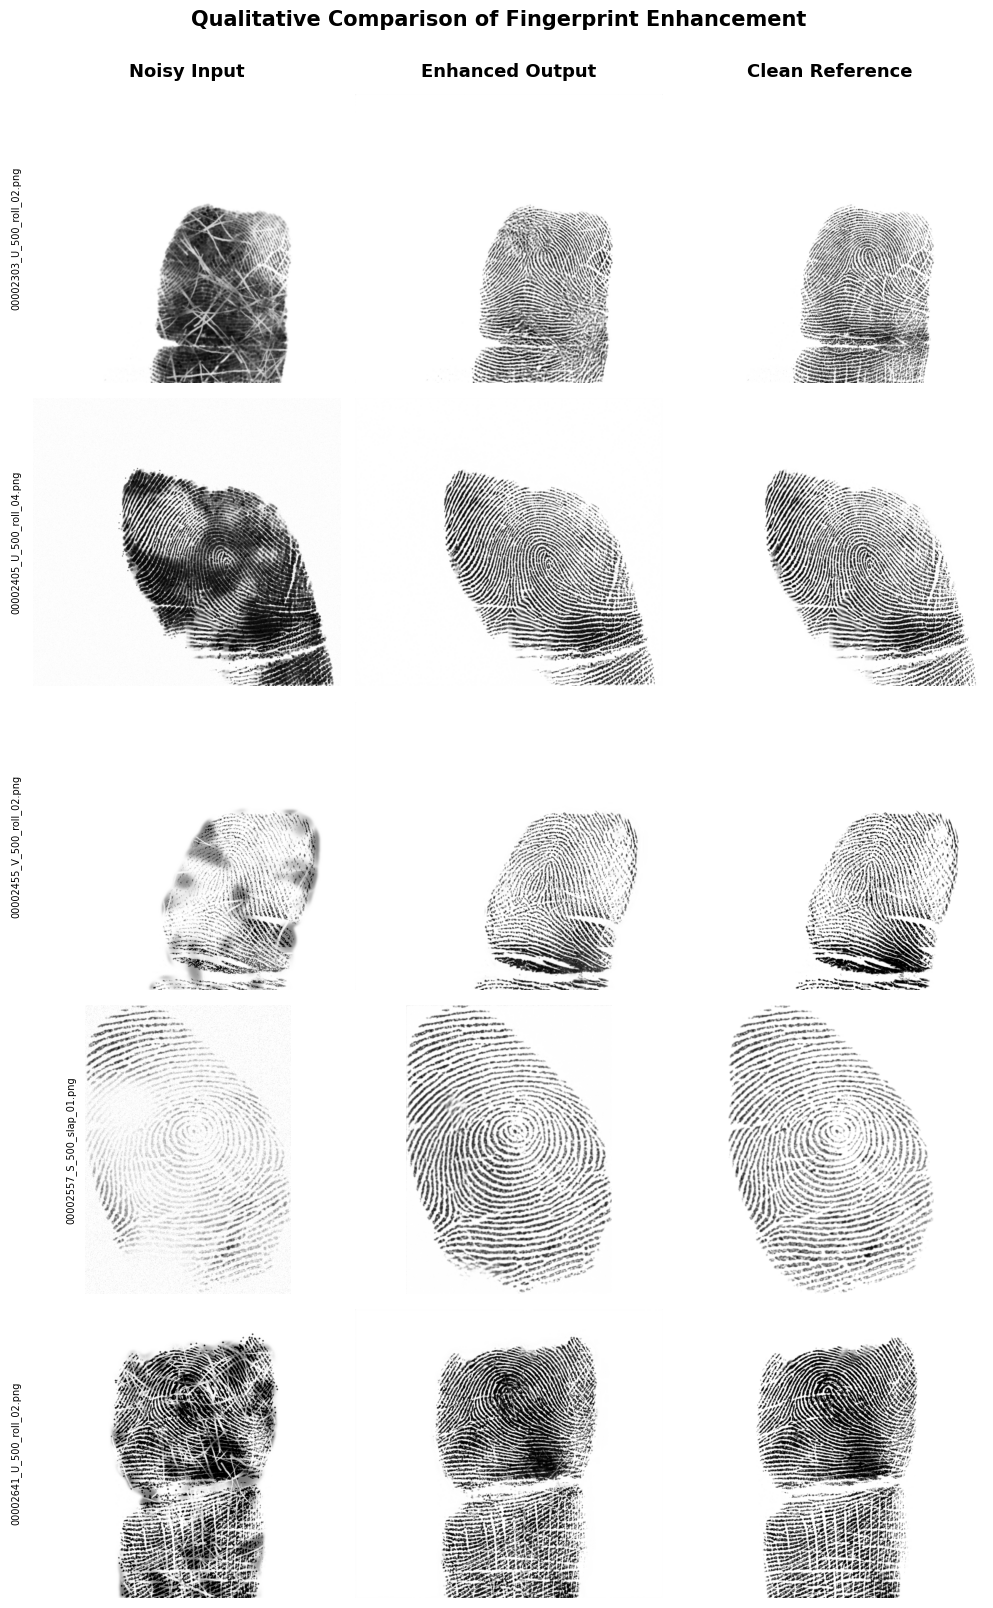


Saved successfully:
/kaggle/working/lfrnet_out_official/fig5_qualitative_comparison.png
/kaggle/working/lfrnet_out_official/fig5_qualitative_comparison.pdf

Fingerprints displayed:
00002303_U_500_roll_02.png
00002405_U_500_roll_04.png
00002455_V_500_roll_02.png
00002557_S_500_slap_01.png
00002641_U_500_roll_02.png


In [34]:

# FIGURE 5: Qualitative Fingerprint Enhancement Comparison
# Uses actual images from /kaggle/working/nfiq_tmp/
# Saves a publication-ready PNG and PDF in OUT_DIR.

import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

BASE = "/kaggle/working/nfiq_tmp"
SAVE_DIR = OUT_DIR

NOISY_DIR = os.path.join(BASE, "noisy")
ENHANCED_DIR = os.path.join(BASE, "enhanced")
CLEAN_DIR = os.path.join(BASE, "clean")

# Verify the directories
for folder in [NOISY_DIR, ENHANCED_DIR, CLEAN_DIR]:
    if not os.path.isdir(folder):
        raise FileNotFoundError(f"Directory not found: {folder}")

# Use only filenames present in all three directories
def get_image_names(folder):
    extensions = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")
    return {
        f for f in os.listdir(folder)
        if f.lower().endswith(extensions)
    }

common_names = sorted(
    get_image_names(NOISY_DIR)
    & get_image_names(ENHANCED_DIR)
    & get_image_names(CLEAN_DIR)
)

print("Matched fingerprints:", len(common_names))

if not common_names:
    raise RuntimeError("No matching filenames found across all three folders.")

# Select up to 5 examples, spread across the sorted matching set.
n_show = min(5, len(common_names))
indices = np.linspace(0, len(common_names) - 1, n_show, dtype=int)
selected_names = [common_names[i] for i in indices]

def load_gray(path):
    with Image.open(path) as im:
        return np.asarray(im.convert("L"))

# Create the comparison figure
fig, axes = plt.subplots(
    n_show, 3,
    figsize=(10, 3.2 * n_show),
    squeeze=False
)

column_titles = ["Noisy Input", "Enhanced Output", "Clean Reference"]

for col, title in enumerate(column_titles):
    axes[0, col].set_title(title, fontsize=13, fontweight="bold", pad=12)

for row, filename in enumerate(selected_names):
    paths = [
        os.path.join(NOISY_DIR, filename),
        os.path.join(ENHANCED_DIR, filename),
        os.path.join(CLEAN_DIR, filename),
    ]

    for col, path in enumerate(paths):
        img = load_gray(path)
        axes[row, col].imshow(img, cmap="gray", vmin=0, vmax=255)
        axes[row, col].axis("off")

    # Identify each fingerprint without obscuring the image.
    axes[row, 0].text(
        -0.04, 0.5, filename,
        transform=axes[row, 0].transAxes,
        rotation=90, va="center", ha="right", fontsize=7
    )

fig.suptitle(
    "Qualitative Comparison of Fingerprint Enhancement",
    fontsize=15, fontweight="bold", y=1.002
)
fig.tight_layout()

os.makedirs(SAVE_DIR, exist_ok=True)

png_path = os.path.join(SAVE_DIR, "fig5_qualitative_comparison.png")
pdf_path = os.path.join(SAVE_DIR, "fig5_qualitative_comparison.pdf")

fig.savefig(png_path, dpi=300, bbox_inches="tight", facecolor="white")
fig.savefig(pdf_path, bbox_inches="tight", facecolor="white")
plt.show()

print("\nSaved successfully:")
print(png_path)
print(pdf_path)
print("\nFingerprints displayed:")
for name in selected_names:
    print(name)


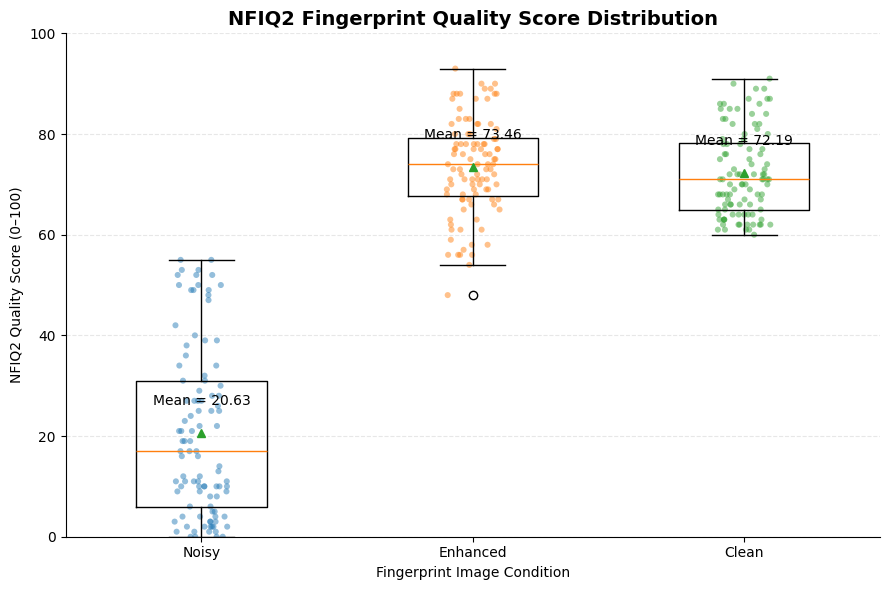

Figure 6 saved:
/kaggle/working/lfrnet_out_official/fig6_nfiq2_distribution.png
/kaggle/working/lfrnet_out_official/fig6_nfiq2_distribution.pdf

NFIQ2 summary:


,count,mean,median,std
Image Condition,,,,
Noisy,100.0,20.63,17.0,16.83
Enhanced,100.0,73.46,74.0,9.51
Clean,100.0,72.19,71.0,8.51


In [36]:

# FIGURE 6: NFIQ2 Quality Score Distribution
# Actual data source: nfiq2_scores_fixed.csv

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

csv_path = os.path.join(OUT_DIR, "nfiq2_scores_fixed.csv")

if not os.path.isfile(csv_path):
    raise FileNotFoundError(f"CSV not found: {csv_path}")

df = pd.read_csv(csv_path)

required = ["score_noisy", "score_enhanced", "score_clean"]
missing = [c for c in required if c not in df.columns]

if missing:
    raise ValueError(
        f"Missing columns: {missing}. Actual columns: {df.columns.tolist()}"
    )

# Convert score columns to numeric values
for col in required:
    df[col] = pd.to_numeric(df[col], errors="coerce")

labels = ["Noisy", "Enhanced", "Clean"]
columns = ["score_noisy", "score_enhanced", "score_clean"]

score_data = [
    df[col].dropna().to_numpy()
    for col in columns
]

if any(len(values) == 0 for values in score_data):
    raise ValueError("At least one score column has no valid numeric values.")

# Publication-quality boxplot with individual sample points
fig, ax = plt.subplots(figsize=(9, 6))

positions = np.arange(1, len(labels) + 1)

ax.boxplot(
    score_data,
    positions=positions,
    widths=0.48,
    showmeans=True,
    showfliers=True,
    patch_artist=False
)

# Plot actual individual scores with deterministic jitter
rng = np.random.default_rng(42)

for x, values in zip(positions, score_data):
    jitter = rng.uniform(-0.10, 0.10, size=len(values))
    ax.scatter(
        x + jitter,
        values,
        s=19,
        alpha=0.48,
        edgecolors="none"
    )

# Annotate actual mean values
for x, values in zip(positions, score_data):
    ax.text(
        x,
        min(98, np.mean(values) + 5),
        f"Mean = {np.mean(values):.2f}",
        ha="center",
        va="bottom",
        fontsize=10
    )

ax.set_xticks(positions)
ax.set_xticklabels(labels)
ax.set_ylabel("NFIQ2 Quality Score (0–100)")
ax.set_xlabel("Fingerprint Image Condition")
ax.set_title(
    "NFIQ2 Fingerprint Quality Score Distribution",
    fontsize=14,
    fontweight="bold"
)

ax.set_ylim(0, 100)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

png_path = os.path.join(OUT_DIR, "fig6_nfiq2_distribution.png")
pdf_path = os.path.join(OUT_DIR, "fig6_nfiq2_distribution.pdf")

fig.savefig(png_path, dpi=300, bbox_inches="tight")
fig.savefig(pdf_path, bbox_inches="tight")
plt.show()

print("Figure 6 saved:")
print(png_path)
print(pdf_path)

# Summary calculated directly from the CSV
summary = df[columns].agg(["count", "mean", "median", "std"]).T
summary.index = labels
summary.index.name = "Image Condition"

print("\nNFIQ2 summary:")
display(summary.round(2))


In [37]:

import os
import zipfile

BASE_DIR = "/kaggle/working"
ZIP_PATH = os.path.join(BASE_DIR, "lfrnet_results_and_nfiq.zip")

FOLDERS_TO_ZIP = [
    "lfrnet_out_official",
    "nfiq_tmp",
]

# Verify folders exist
for folder in FOLDERS_TO_ZIP:
    folder_path = os.path.join(BASE_DIR, folder)
    if not os.path.isdir(folder_path):
        raise FileNotFoundError(f"Folder not found: {folder_path}")

# Create ZIP containing only the requested folders
file_count = 0

with zipfile.ZipFile(
    ZIP_PATH, mode="w", compression=zipfile.ZIP_DEFLATED
) as zf:
    for folder in FOLDERS_TO_ZIP:
        folder_path = os.path.join(BASE_DIR, folder)

        for root, dirs, files in os.walk(folder_path):
            for filename in files:
                full_path = os.path.join(root, filename)
                arcname = os.path.relpath(full_path, BASE_DIR)
                zf.write(full_path, arcname)
                file_count += 1

print("ZIP created successfully!")
print("Path:", ZIP_PATH)
print("Files included:", file_count)
print("ZIP size (GB):", round(os.path.getsize(ZIP_PATH) / (1024**3), 3))

# Verify the ZIP contents
with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    included_roots = sorted({
        name.split("/")[0]
        for name in zf.namelist()
        if name and not name.endswith("/")
    })

print("\nTop-level folders inside ZIP:")
for folder in included_roots:
    print(" -", folder)

print("\nDownload your ZIP using the Kaggle Output panel.")


ZIP created successfully!
Path: /kaggle/working/lfrnet_results_and_nfiq.zip
Files included: 328
ZIP size (GB): 0.073

Top-level folders inside ZIP:
 - lfrnet_out_official
 - nfiq_tmp

Download your ZIP using the Kaggle Output panel.
